# Learned Bloom Filters — 1. Problem & Data
**CS328 Project · IIT Gandhinagar**

### The problem: fast, memory-cheap set membership
A **Bloom filter** answers *"is item x in set S?"* using a tiny bit-array. It can say
**"definitely not in S"** or **"probably in S"** — it never misses a true member
(**zero false negatives**) but occasionally raises a **false positive**. Smaller memory
means more false positives. Bloom filters power databases, browsers, and CDNs.

### The learned idea (Kraska et al., 2018)
A standard Bloom filter ignores any *pattern* in the keys. If the set has learnable
structure, we can train a small classifier (an **oracle**) to guess membership and fall
back on a small backup Bloom filter for the keys it would miss — keeping the
zero-false-negative guarantee while using **less total memory**.

### Our task
Store a blocklist of **malicious URLs** (the set S). The structure must never miss a
malicious URL and must rarely flag a benign one. We benchmark a standard Bloom filter
against the **Learned**, **Sandwiched** and **Partitioned** designs.

**Dataset:** ~195,000 URLs, balanced malicious/benign, with overlapping lengths
(so the model must learn real content patterns, not a trivial shortcut).

In [1]:
# Download the URL dataset (~195k URLs, labelled malicious=1 / benign=0)
import os
import ssl
import urllib.request
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/incertum/cyber-matrix-ai/"
    "master/Malicious-URL-Detection-Deep-Learning/data/url_data_mega_deep_learning.csv"
)

os.makedirs("data", exist_ok=True)

if not os.path.exists("data/url_data.csv"):
    # Relax TLS just for this one download (some Colab images lag on CA certs)
    ctx = ssl.create_default_context()
    ctx.check_hostname = False
    ctx.verify_mode = ssl.CERT_NONE
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120, context=ctx) as response:
        with open("data/url_data.csv", "wb") as out:
            out.write(response.read())

print("Dataset ready.")

Dataset ready.


Load the data, remove duplicates, and look at the class balance and URL lengths.

In [2]:
df = pd.read_csv("data/url_data.csv")
df.columns = [c.strip() for c in df.columns]
df = df.dropna().drop_duplicates("url").reset_index(drop=True)

print("Total URLs:", len(df))
print("Malicious :", int(df.isMalicious.sum()))
print("Benign    :", int((df.isMalicious == 0).sum()))
df.head()

Total URLs: 170532
Malicious : 73367
Benign    : 97165


,url,isMalicious
0,songlyrics.com/news/riffd-the-shins-heartworms,0
1,imaging-resource.com/PRODS/olympus-e-m1-ii/oly...,0
2,gosugamers.net/lol/streams,0
3,thingiverse.com/corkyzett/collections/intlwome...,0
4,bausch.com/our-products/contact-lens-care/spec...,0


                  mean   50%  min     max
isMalicious                              
0            51.161910  43.0  3.0  1316.0
1            55.981395  38.0  1.0  4011.0


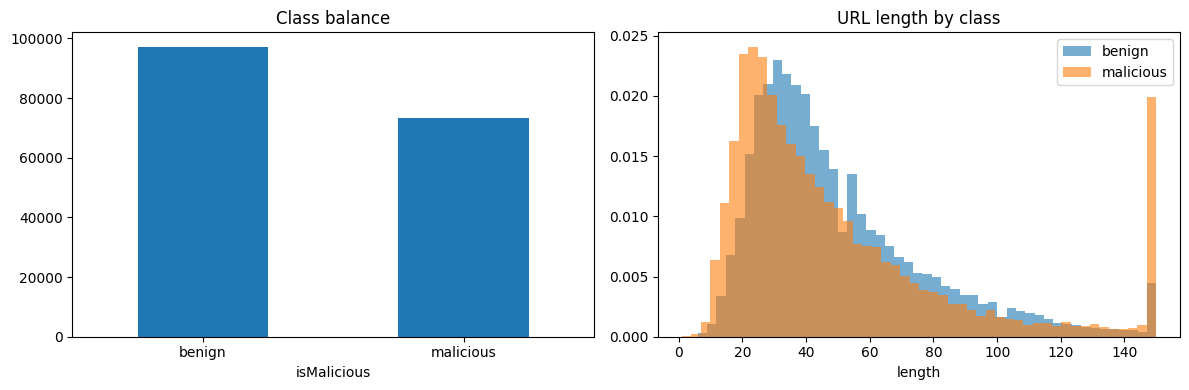

In [3]:
import matplotlib.pyplot as plt

# Check there is no trivial length difference the model could exploit
df["length"] = df.url.str.len()
print(df.groupby("isMalicious")["length"].describe()[["mean", "50%", "min", "max"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

counts = df.isMalicious.value_counts().rename({0: "benign", 1: "malicious"})
counts.plot.bar(ax=ax[0], rot=0, title="Class balance")

for label, name in [(0, "benign"), (1, "malicious")]:
    lengths = df[df.isMalicious == label]["length"].clip(0, 150)
    ax[1].hist(lengths, bins=50, alpha=0.6, density=True, label=name)
ax[1].set_title("URL length by class")
ax[1].set_xlabel("length")
ax[1].legend()

plt.tight_layout()
plt.show()

In [4]:
# What does each class actually look like?
print("Malicious examples:")
for url in df[df.isMalicious == 1].url.head(4):
    print("  ", url)

print()
print("Benign examples:")
for url in df[df.isMalicious == 0].url.head(4):
    print("  ", url)

Malicious examples:
   at.ua/8/recovery
   giveitallhereqq.com/69.exe
   bget.ru
   shucksbr.com/files/impotsfr

Benign examples:
   songlyrics.com/news/riffd-the-shins-heartworms
   imaging-resource.com/PRODS/olympus-e-m1-ii/olympus-e-m1-iiA.HTM
   gosugamers.net/lol/streams
   thingiverse.com/corkyzett/collections/intlwomensday


**Takeaway.** The classes are balanced and the lengths overlap, so any signal must come from *content* (character patterns, suspicious tokens). Next: the standard Bloom filter baseline.